In [1]:
from rdkit import Chem
from rdkit import FilterCatalog

catalog = FilterCatalog.FilterCatalog()
for k, v in smarts_library.items():
    # create RDKit molecule
    m = Chem.MolFromSmarts(v)

    # create SMARTS matcher
    sm = FilterCatalog.SmartsMatcher(m)

    # add entry to FilterCatalog
    entry = FilterCatalog.FilterCatalogEntry(k, sm)
    catalog.AddEntry(entry)

smiles = "C1N=CC=C(C(=O)Cl)C=1"
matches = catalog.GetMatches(Chem.MolFromSmiles(smiles))

for match in matches:
    print(match.GetDescription())

ImportError: cannot import name 'FilterCatalog' from 'rdkit' (/home/baolingjie/anaconda3/envs/img2smiles/lib/python3.8/site-packages/rdkit/__init__.py)

In [ ]:
smiles = "O=C(O)c1c[nH]c2c(ccc3cccnc32)c1=O"
mol = Chem.MolFromSmiles(smiles)
mol

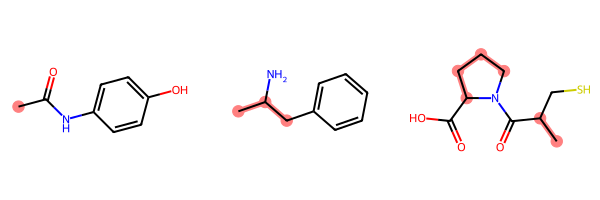

In [2]:
from rdkit import Chem
from rdkit.Chem import Draw
mols = ['CC(=O)Nc1ccc(O)cc1', 'CC(N)Cc1ccccc1', 'CC(CS)C(=O)N1CCCC1C(=O)O']
mols = list(map(Chem.MolFromSmiles, mols))
sub = Chem.MolFromSmarts('[#6]!:[#6]')
highlights = [[a[0] for a in m.GetSubstructMatches(sub)] for m in mols]
Draw.MolsToGridImage(mols, highlightAtomLists=highlights)

In [4]:
from rdkit import Chem
smiles_list = ['C12=CC=CC=C1C3=CC=CC4=C3C2=CC=C4', 
                'C12=CC=CC=C1C3=CC=C4C5=C(C=CC2=C35)C6=C4C=CC=C6', 
                'C12=CC=CC=C1C3=CC=C4C5=C(C=CC2=C35)C=C4', 
                'C12=CC=CC=C1C3=CC=C4C5=C(C=CC2=C35)C6=C4C=C7CCCCC7=C6', 
                'C12=CC=CC=C1C3=CC=C4C5=C(C=CC2=C35)C6=C4C=C7CC8=CC=CC=C8CC7=C6', 
                'c1ccccc1']

mols = list(map(Chem.MolFromSmiles, smiles_list))

pattern = Chem.MolFromSmarts('[#6]12~[#6][#6]~[#6][#6]~[#6]1[#6]3~[#6][#6]~[#6][#6]4~[#6]3[#6]2~[#6][#6]~[#6]4')
for idx,smiles in enumerate(smiles_list):    
    m = Chem.MolFromSmiles(smiles)    
    print("Structure {}: pattern found {}".format(idx+1,m.HasSubstructMatch(pattern)))


Structure 1: pattern found True
Structure 2: pattern found True
Structure 3: pattern found True
Structure 4: pattern found True
Structure 5: pattern found True
Structure 6: pattern found False


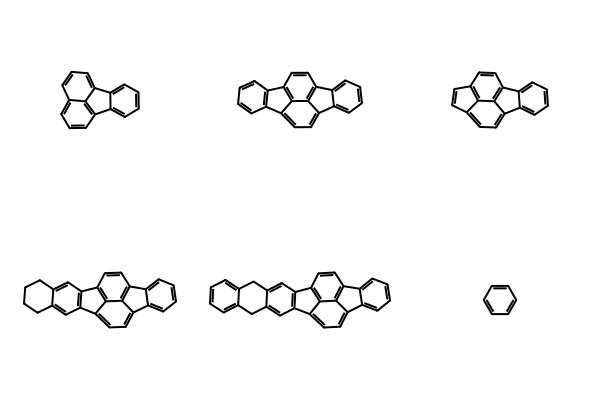

In [6]:
Draw.MolsToGridImage(mols)

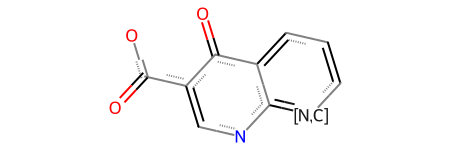

In [7]:
qry = Chem.MolFromSmarts('OC(C1=CNC2=[N,C]C=CC=C2C1=O)=O')
qry

In [9]:
print(Chem.MolToMolBlock(qry, forceV3000=True))


     RDKit          2D

  0  0  0  0  0  0  0  0  0  0999 V3000
M  V30 BEGIN CTAB
M  V30 COUNTS 14 15 0 0 0
M  V30 BEGIN ATOM
M  V30 1 O -3.000000 -5.196152 0.000000 0
M  V30 2 C -1.500000 -5.196152 0.000000 0
M  V30 3 C -0.750000 -3.897114 0.000000 0
M  V30 4 C 0.750000 -3.897114 0.000000 0
M  V30 5 N 1.500000 -2.598076 0.000000 0
M  V30 6 C 0.750000 -1.299038 0.000000 0
M  V30 7 [N,C] 1.500000 0.000000 0.000000 0
M  V30 8 C 0.750000 1.299038 0.000000 0
M  V30 9 C -0.750000 1.299038 0.000000 0
M  V30 10 C -1.500000 0.000000 0.000000 0
M  V30 11 C -0.750000 -1.299038 0.000000 0
M  V30 12 C -1.500000 -2.598076 0.000000 0
M  V30 13 O -3.000000 -2.598076 0.000000 0
M  V30 14 O -0.750000 -6.495191 0.000000 0
M  V30 END ATOM
M  V30 BEGIN BOND
M  V30 1 6 1 2
M  V30 2 6 2 3
M  V30 3 2 3 4
M  V30 4 6 4 5
M  V30 5 6 5 6
M  V30 6 2 6 7
M  V30 7 6 7 8
M  V30 8 2 8 9
M  V30 9 6 9 10
M  V30 10 2 10 11
M  V30 11 6 11 12
M  V30 12 2 12 13
M  V30 13 2 2 14
M  V30 14 6 12 3
M  V30 15 6 11 6
M  V30 END

In [ ]:
qry = Chem.MolFromSmarts(Chem.MolToSmarts(Chem.MolFromSmarts(Chem.MolToSmarts(qry))))